# Non-Traffic Citations in Pittsburgh
**Yifan Hao — CMPINF 0010 Final Project**

## Introduction
Our group is studying public-safety-related incidents across Pittsburgh neighborhoods. My submetric is the number of non-traffic citations issued by Pittsburgh Police. I use the WPRDC historical Non-Traffic Citations dataset to compare neighborhoods. A smaller number of citations is treated as a better score for this specific metric, not as proof that a neighborhood is objectively safer.

**Source:** [WPRDC Non-Traffic Citations](https://data.wprdc.org/dataset/non-traffic-citations/resource/6b11e87d-1216-463d-bbd3-37460e539d86). Historical coverage ends in 2023.

**Important:** Agree with your teammates on a common year range. The default below is 2018–2022, but change it to match your team.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

resource_id = "6b11e87d-1216-463d-bbd3-37460e539d86"
url = f"https://data.wprdc.org/datastore/dump/{resource_id}"

df = pd.read_csv(url, low_memory=False)
print("Raw rows:", len(df))
print("Columns:", list(df.columns))
df.head()

Raw rows: 16295
Columns: ['_id', 'PK', 'CCR', 'GENDER', 'RACE', 'AGE', 'CITEDTIME', 'INCIDENTLOCATION', 'OFFENSES', 'NEIGHBORHOOD', 'ZONE', 'INCIDENTTRACT', 'COUNCIL_DISTRICT', 'PUBLIC_WORKS_DIVISION', 'X', 'Y']


,_id,PK,CCR,GENDER,RACE,AGE,CITEDTIME,INCIDENTLOCATION,OFFENSES,NEIGHBORHOOD,ZONE,INCIDENTTRACT,COUNCIL_DISTRICT,PUBLIC_WORKS_DIVISION,X,Y
0,1,1078081,16157849,M,B,29.0,2016-08-22T23:45:00.000,"200 Block N DITHRIDGE ST PITTSBURGH, PA",5503(a)(2) DISORDERLY CONDUCT - UNREASONABLE N...,North Oakland,4,507,8.0,3.0,-79.951692,40.449311
1,2,1078082,16157849,M,W,21.0,2016-08-22T23:45:00.000,"200 Block N DITHRIDGE ST PITTSBURGH, PA",5503(a)(2) DISORDERLY CONDUCT - UNREASONABLE N...,North Oakland,4,507,8.0,3.0,-79.951692,40.449311
2,3,1078083,16159579,NaN,NaN,NaN,2016-08-25T11:10:00.000,"NORTH PARK PITTSBURGH, PA",5505 Public Drunkenness,Allegheny Center,1,2204,NaN,NaN,NaN,NaN
3,4,1078084,16159780,M,B,22.0,2016-08-25T16:42:00.000,"7200 Block FRANKSTOWN AV PITTSBURGH, PA","6501(a)(1) Scattering Rubbish; Any waste, dang...",Homewood South,5,1303,9.0,2.0,-79.896254,40.457329
4,5,1078085,16161591,F,W,22.0,2016-08-28T00:58:00.000,"6100 Block BERLIN WY PITTSBURGH, PA",5503(a)(2) DISORDERLY CONDUCT - UNREASONABLE N...,Upper Lawrenceville,2,1011,7.0,2.0,-79.946664,40.485403


## The Metric
I count non-traffic citations for each neighborhood, within the same years used by the rest of the group. I rank neighborhoods in ascending order: fewer recorded citations means a higher rank on this submetric. This is a **count**, not a population-adjusted rate. Citations may be affected by neighborhood population, activity levels, reporting, and policing practices.

In [10]:
data = df.copy()
data.columns = data.columns.str.strip().str.upper()
data["CITEDTIME"] = pd.to_datetime(data["CITEDTIME"], errors="coerce")
data["NEIGHBORHOOD"] = data["NEIGHBORHOOD"].astype("string").str.strip()
data = data.dropna(subset=["CITEDTIME", "NEIGHBORHOOD"])
data = data[data["NEIGHBORHOOD"].ne("")]

# Change these two years after agreeing with your teammates.
start_year = 2018
end_year = 2022
data = data[data["CITEDTIME"].dt.year.between(start_year, end_year)].copy()

# Remove locations outside Pittsburgh
excluded = [
    "Outside County",
    "Outside State",
    "Outside City",
    "Mt. Oliver Boro"
]

data = data[~data["NEIGHBORHOOD"].isin(excluded)]

print("Rows after cleaning and date filter:", len(data))
print("Neighborhoods represented:", data["NEIGHBORHOOD"].nunique())
print("Years:", sorted(data["CITEDTIME"].dt.year.unique()))

Rows after cleaning and date filter: 9813
Neighborhoods represented: 90
Years: [np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022)]


## The Best Neighborhood According to This Metric

In [11]:
citation_counts = (data.groupby("NEIGHBORHOOD").size()
                   .sort_values(ascending=True)
                   .rename("Citation_Count"))
if citation_counts.empty:
    raise ValueError("No records in the chosen years. Change start_year/end_year and rerun.")
ranking = citation_counts.reset_index()
ranking.insert(
    0,
    "Rank",
    ranking["Citation_Count"].rank(method="min").astype(int)
)
display(ranking.head(15))
print("Fewest recorded citations:", ranking.iloc[0]["NEIGHBORHOOD"], "—", ranking.iloc[0]["Citation_Count"])

,Rank,NEIGHBORHOOD,Citation_Count
0,1,Chartiers City,2
1,1,Summer Hill,2
2,3,Ridgemont,3
3,3,St. Clair,3
4,5,Spring Garden,4
5,6,Hays,5
6,6,Swisshelm Park,5
7,8,New Homestead,6
8,8,Arlington Heights,6
9,10,Allegheny West,7


Fewest recorded citations: Chartiers City — 2


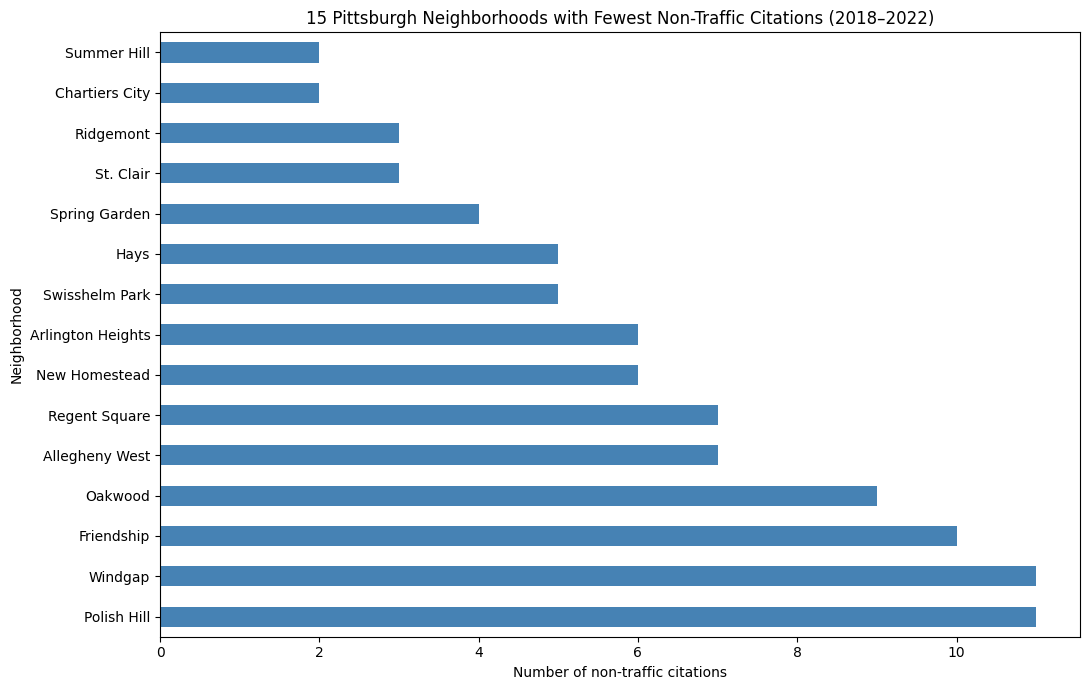

In [12]:
top_15 = citation_counts.head(15).sort_values(ascending=False)
ax = top_15.plot(kind="barh", figsize=(11, 7), color="steelblue")
ax.set_title(f"15 Pittsburgh Neighborhoods with Fewest Non-Traffic Citations ({start_year}–{end_year})")
ax.set_xlabel("Number of non-traffic citations")
ax.set_ylabel("Neighborhood")
plt.tight_layout()
plt.show()

### Interpretation
Based on the Non-Traffic Citations dataset from 2018 to 2022, Chartiers City and Summer Hill tied for the lowest number of recorded citations, with only 2 each. Under our metric, fewer citations indicate a better neighborhood ranking. However, citation counts alone do not necessarily reflect actual neighborhood safety because differences in population size and policing practices may influence the results.

## Conclusion
Personally, I prefer Oakland because I spend most of my time there as a University of Pittsburgh student. It is convenient for classes, restaurants, and other daily activities. However, my data analysis shows that Chartiers City and Summer Hill have fewer recorded non-traffic citations. This demonstrates that the neighborhood with the lowest citation count is not necessarily my personal favorite, since convenience and accessibility also matter when choosing where to live.